# Using Machine Learning to Solve for RSI SMA period
Selection system: two approaches
- Create an algo that performs sentiment and fundamental analysis on crypto, giving it a score then we pick the best performers
- Identify by price action. Price movement 15m, 1hr, 4hr all positive. Then volume.

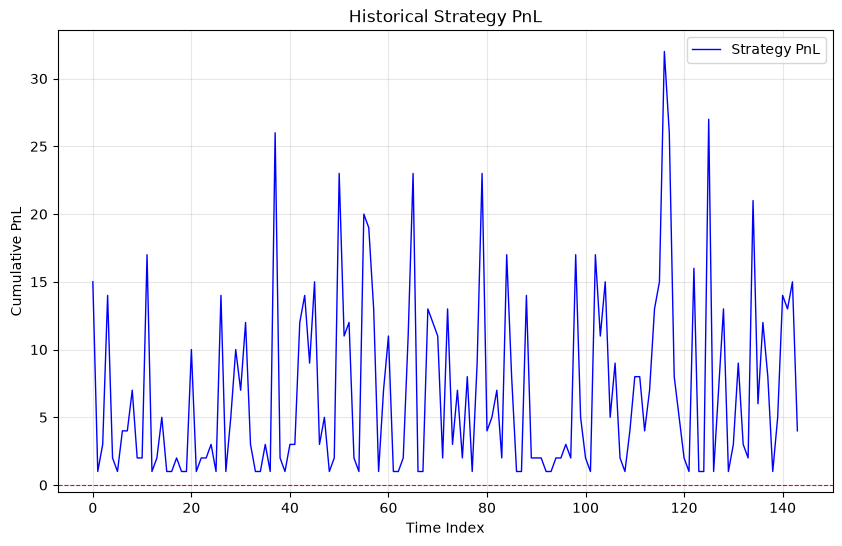

In [11]:
# Add the project root (one level up from /research) to the path
import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

import pandas as pd
from utils.indicators import *
from utils.engine import *

df_price = pd.read_csv("./csv/btc_ohlcv_data.csv")
df_orderbook = pd.read_csv("./csv/BTCUSDT_orderbook.csv")
df_trades = pd.read_csv("./csv/BTCUSDT_trades.csv")

price_clean = np.asanyarray(df_price['close'], dtype=float)
rsi_2 = get_wilders_rsi(np.diff(price_clean), 2)
rsi_14 = get_wilders_rsi(np.diff(price_clean), 14)
rsi_14_sma = sma(rsi_14, 14)

# 1. Calculate the indicators
price_clean = np.asanyarray(df_price['close'], dtype=float)
diffs = np.diff(price_clean)

# 2. Get the raw RSI arrays
rsi_14_raw = get_wilders_rsi(diffs, 14)
rsi_14_sma_raw = sma(rsi_14_raw, 14)

# 3. Create full-length arrays filled with NaN
rsi_14 = np.full(len(df_price), np.nan)
rsi_14_sma = np.full(len(df_price), np.nan)

rsi_14[-len(rsi_14_raw):] = rsi_14_raw
rsi_14_sma[-len(rsi_14_sma_raw):] = rsi_14_sma_raw

# 5. Assign to DataFrame
df_price['rsi_14'] = rsi_14
df_price['sma_14'] = rsi_14_sma

# Call it with your variables, explicitly passing labels so the chart is clear
df_price['rsi_above_sma'] = df_price['rsi_14'] > df_price['sma_14']

# 2. Identify where the condition changes (this creates a new "block" for every switch)
df_price['block'] = (df_price['rsi_above_sma'] != df_price['rsi_above_sma'].shift()).cumsum()

# 3. Group by the condition and block to count the duration of each streak
streak_durations = df_price.groupby(['rsi_above_sma', 'block']).size().reset_index(name='duration')

plot_one(streak_durations['duration'])